In [7]:
# %%
# =========================================================
# 1. IMPORTS & CONFIGURATION
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import os
import warnings

# BigQuery Import
from google.cloud import bigquery

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    precision_recall_curve, f1_score, auc, classification_report
)
from lightgbm import LGBMRegressor, LGBMClassifier
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Create data directory for our physical splits
os.makedirs('data_splits', exist_ok=True)

In [ ]:
# %%
# =========================================================
# 2. DATA EXTRACTION & THE "QUARANTINE" SPLIT
# =========================================================
print("Extracting data from BigQuery...")

# --- OLD CSV LOGIC (Commented out) ---
# df = pd.read_csv('Final Data.csv')

# --- NEW BIGQUERY LOGIC ---
GCP_PROJECT_ID = os.environ.get("GCP_PROJECT_ID", "adk-mini-project")
bq_client = bigquery.Client(project=GCP_PROJECT_ID)

master_query = """
SELECT * FROM `adk-mini-project.technicals.train_data`
"""

# NOTE: Comment this out and use the query above when ready to run live. 
# For now, if you are testing, you can uncomment the CSV read below.
df = bq_client.query(master_query).to_dataframe() 
# df = pd.read_csv('Final Data.csv') 

print(f"Data Extracted. Total Rows: {len(df)}")

# 1. Ensure Temporal Types & Sorting
df['parsed_period'] = pd.to_datetime(df['parsed_period'])
df['t0_trading_date'] = pd.to_datetime(df['t0_trading_date'])
df = df.sort_values(by='t0_trading_date').reset_index(drop=True)

# 2. Define the Universal Risk Target (Drawdown worse than -15%)
RISK_THRESHOLD = -0.15
df['target_is_risky'] = (df['target_max_drawdown_pct'] <= RISK_THRESHOLD).astype(int)

# 3. Chronological "Quarantine" Split (Last 2 Quarters = Blind Test)
unique_quarters = sorted(df['parsed_period'].unique())
test_quarters = unique_quarters[-2:]

test_mask = df['parsed_period'].isin(test_quarters)
train_val_mask = ~test_mask

df_train_val = df[train_val_mask]
df_test = df[test_mask]

# 4. Save physically to disk to freeze the sets
df_train_val.to_csv('data_splits/train_val_quarantine.csv', index=False)
df_test.to_csv('data_splits/test_quarantine.csv', index=False)

print(f"🔒 Data Quarantined and Saved.")
print(f"   -> Train/Val Rows: {len(df_train_val)}")
print(f"   -> Blind Test Rows: {len(df_test)}")
print(f"   -> Test Quarters: {test_quarters[0].strftime('%Y-%m')} & {test_quarters[1].strftime('%Y-%m')}")

# Clear the master dataframe from memory to prevent accidental leakage
del df

Extracting data from BigQuery...
Data Extracted. Total Rows: 16744
🔒 Data Quarantined and Saved.
   -> Train/Val Rows: 14426
   -> Blind Test Rows: 2318
   -> Test Quarters: 2025-12 & 2026-03


In [9]:
# =========================================================
# HELPER: UPLOAD ARTIFACTS TO GCS
# =========================================================
from google.cloud import storage
import os

def save_and_upload_plot(fig, filename_prefix):
    """Saves a matplotlib figure locally and uploads it to GCS."""
    
    # 1. Setup paths
    run_date_str = datetime.now().strftime("%Y-%m-%d")
    bucket_name = "adk-mini-project-ml-artifacts"  # Replace with your actual bucket name
    local_filename = f"{filename_prefix}.png"
    gcs_path = f"runs/{run_date_str}/plots/{local_filename}"
    
    # 2. Save locally
    fig.savefig(local_filename, bbox_inches='tight', dpi=300)
    
    # 3. Upload to GCS
    try:
        storage_client = storage.Client(project=GCP_PROJECT_ID)
        bucket = storage_client.bucket(bucket_name)
        blob = bucket.blob(gcs_path)
        blob.upload_from_filename(local_filename)
        print(f"📈 Uploaded plot to gs://{bucket_name}/{gcs_path}")
    except Exception as e:
        print(f"⚠️ Could not upload plot to GCS: {e}")
    finally:
        # 4. Clean up local file
        if os.path.exists(local_filename):
            os.remove(local_filename)

# --- How to use it in your existing code ---
# Replace plt.show() in your plotting functions with:
# save_and_upload_plot(fig, "shap_importance_max_upside")
# plt.show() # You can still call this if you want to see it in your notebook

In [10]:
# %%
# =========================================================
# 3. RELOAD ISOLATED SETS & DEFINE FEATURES
# =========================================================
print("\nReloading isolated datasets for training...")
train_val_data = pd.read_csv('data_splits/train_val_quarantine.csv', parse_dates=['parsed_period', 't0_trading_date'])
test_data = pd.read_csv('data_splits/test_quarantine.csv', parse_dates=['parsed_period', 't0_trading_date'])

target_cols = ['target_max_upside_pct', 'target_max_drawdown_pct', 'target_avg_price_pct', 'target_is_risky']
train_val_data = train_val_data.dropna(subset=target_cols).reset_index(drop=True)
test_data = test_data.dropna(subset=target_cols).reset_index(drop=True)

categorical_features = ['sector_l2', 'sector_l3']

numeric_features = [
    'ttm_revenue', 'historical_pe', 'historical_market_cap', 
    'op_margin_pct', 'net_profit_margin_pct', 'rev_growth_yoy', 
    'eps_growth_yoy', 'fii_change_qoq', 'dii_change_qoq', 'promoter_change_qoq',
    'cfo_to_net_profit_ratio', 'cash_conversion_cycle_days', 'roce_pct',
    'dist_from_200sma', 'natr_14d', 'obv_90d_slope_norm', 'return_90d', 
    'historical_peg', 'historical_ps', 'rs_90d_percentile', 
    'npm_sector_l2_percentile', 'rev_growth_yoy_l2_percentile', 'roce_sector_l2_percentile'
]

features = categorical_features + numeric_features

# Separate X and y
X_train_val = train_val_data[features]
y_train_val_up = train_val_data['target_max_upside_pct']
y_train_val_down = train_val_data['target_max_drawdown_pct']
y_train_val_avg = train_val_data['target_avg_price_pct']
y_train_val_risk = train_val_data['target_is_risky']

X_test = test_data[features]
y_test_up = test_data['target_max_upside_pct']
y_test_down = test_data['target_max_drawdown_pct']
y_test_avg = test_data['target_avg_price_pct']
y_test_risk = test_data['target_is_risky']

print("✅ Features and Targets successfully mapped from isolated files.")


Reloading isolated datasets for training...
✅ Features and Targets successfully mapped from isolated files.


In [11]:
# %%
# =========================================================
# 4. SKLEARN PIPELINES ARCHITECTURE
# =========================================================
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
        ('num', 'passthrough', numeric_features)
    ])

# Base LightGBM configurations
lgbm_params_reg = {'n_estimators': 200, 'learning_rate': 0.05, 'random_state': 42, 'verbose': -1}
lgbm_params_clf = {'n_estimators': 200, 'learning_rate': 0.05, 'random_state': 42, 'class_weight': 'balanced', 'verbose': -1}

# Assemble Pipelines
pipe_upside = Pipeline([('preprocessor', preprocessor), ('model', LGBMRegressor(**lgbm_params_reg))])
pipe_drawdown = Pipeline([('preprocessor', preprocessor), ('model', LGBMRegressor(**lgbm_params_reg))])
pipe_avg = Pipeline([('preprocessor', preprocessor), ('model', LGBMRegressor(**lgbm_params_reg))])
pipe_risk = Pipeline([('preprocessor', preprocessor), ('model', LGBMClassifier(**lgbm_params_clf))])

print("✅ LightGBM Pipelines Assembled.")

✅ LightGBM Pipelines Assembled.


In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_squared_error, 
    mean_absolute_error, 
    mean_absolute_percentage_error, 
    r2_score, 
    precision_recall_curve, 
    auc
)

# =========================================================
# HELPER FUNCTIONS FOR METRICS
# =========================================================
def calculate_wape(y_true, y_pred):
    """Calculates Weighted Absolute Percentage Error (WAPE)."""
    return np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))

def get_regression_metrics(y_true, y_pred):
    """Calculates all requested regression metrics (INR terms & percentages)."""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    wape = calculate_wape(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return {'mse': mse, 'rmse': rmse, 'mae': mae, 'mape': mape, 'wape': wape, 'r2': r2}

# =========================================================
# 5. EXPANDING WINDOW VALIDATION (Isolated Train/Val set)
# =========================================================
print("\nStarting Expanding Window Validation...")

tv_quarters = sorted(train_val_data['parsed_period'].unique())

# Dictionaries to store metric lists across the 4 windows
val_results = {
    'upside': {'mse': [], 'rmse': [], 'mae': [], 'mape': [], 'wape': [], 'r2': []},
    'drawdown': {'mse': [], 'rmse': [], 'mae': [], 'mape': [], 'wape': [], 'r2': []},
    'avg_price': {'mse': [], 'rmse': [], 'mae': [], 'mape': [], 'wape': [], 'r2': []},
    'risk_auc': []
}

# Validate across the last 4 quarters
for i in range(len(tv_quarters) - 4, len(tv_quarters)):
    train_qtrs_window = tv_quarters[:i]
    val_qtr_window = [tv_quarters[i]]
    
    idx_train = train_val_data[train_val_data['parsed_period'].isin(train_qtrs_window)].index
    idx_val = train_val_data[train_val_data['parsed_period'].isin(val_qtr_window)].index
    
    # Train
    pipe_upside.fit(X_train_val.loc[idx_train], y_train_val_up.loc[idx_train])
    pipe_drawdown.fit(X_train_val.loc[idx_train], y_train_val_down.loc[idx_train])
    pipe_avg.fit(X_train_val.loc[idx_train], y_train_val_avg.loc[idx_train]) # Added to val loop for comparison
    pipe_risk.fit(X_train_val.loc[idx_train], y_train_val_risk.loc[idx_train])
    
    # Predict
    preds_up = pipe_upside.predict(X_train_val.loc[idx_val])
    preds_down = pipe_drawdown.predict(X_train_val.loc[idx_val])
    preds_avg = pipe_avg.predict(X_train_val.loc[idx_val])
    preds_risk_proba = pipe_risk.predict_proba(X_train_val.loc[idx_val])[:, 1]
    
    # Evaluate Upside
    up_mets = get_regression_metrics(y_train_val_up.loc[idx_val], preds_up)
    for k in val_results['upside']: val_results['upside'][k].append(up_mets[k])
        
    # Evaluate Drawdown
    down_mets = get_regression_metrics(y_train_val_down.loc[idx_val], preds_down)
    for k in val_results['drawdown']: val_results['drawdown'][k].append(down_mets[k])

    # Evaluate Avg Price
    avg_mets = get_regression_metrics(y_train_val_avg.loc[idx_val], preds_avg)
    for k in val_results['avg_price']: val_results['avg_price'][k].append(avg_mets[k])
        
    # Evaluate Risk
    precision, recall, _ = precision_recall_curve(y_train_val_risk.loc[idx_val], preds_risk_proba)
    val_results['risk_auc'].append(auc(recall, precision))

# Average out the validation metrics
val_summary = {
    'upside': {k: np.mean(v) for k, v in val_results['upside'].items()},
    'drawdown': {k: np.mean(v) for k, v in val_results['drawdown'].items()},
    'avg_price': {k: np.mean(v) for k, v in val_results['avg_price'].items()},
    'risk_auc': np.mean(val_results['risk_auc'])
}

# =========================================================
# 6. EXTERNAL TEST SET EVALUATION
# =========================================================
print("\nRetraining models on FULL Train+Val Dataset for Test Evaluation...")

pipe_upside.fit(X_train_val, y_train_val_up)
pipe_drawdown.fit(X_train_val, y_train_val_down)
pipe_avg.fit(X_train_val, y_train_val_avg)
pipe_risk.fit(X_train_val, y_train_val_risk)

test_preds_up = pipe_upside.predict(X_test)
test_preds_down = pipe_drawdown.predict(X_test)
test_preds_avg = pipe_avg.predict(X_test)
test_preds_risk_proba = pipe_risk.predict_proba(X_test)[:, 1]

# Compute Test Metrics
test_summary = {
    'upside': get_regression_metrics(y_test_up, test_preds_up),
    'drawdown': get_regression_metrics(y_test_down, test_preds_down),
    'avg_price': get_regression_metrics(y_test_avg, test_preds_avg)
}

# Risk Test Metric
test_precision, test_recall, _ = precision_recall_curve(y_test_risk, test_preds_risk_proba)
test_summary['risk_auc'] = auc(test_recall, test_precision)

# =========================================================
# 7. METRICS COMPARISON SUMMARY (INR TERMS)
# =========================================================
print("\n" + "="*85)
print(f"{'FINAL PERFORMANCE COMPARISON (VALIDATION VS TESTING)':^85}")
print("="*85)

def print_comparison(target_name, val_dict, test_dict):
    print(f"\nTarget: {target_name}")
    print("-" * 85)
    print(f"{'Metric':<10} | {'Validation (Avg)':<25} | {'Test (Blind)':<25} | {'Difference (Test-Val)'}")
    print("-" * 85)
    metrics_to_print = ['mae', 'rmse', 'mse', 'mape', 'wape']
    for m in metrics_to_print:
        v = val_dict[m]
        t = test_dict[m]
        diff = t - v
        # Format as percentage for MAPE/WAPE, standard float for INR metrics
        if m in ['mape', 'wape']:
            print(f"{m.upper():<10} | {v:.2%}                  | {t:.2%}                  | {diff:+.2%}")
        else:
            print(f"{m.upper():<10} | {v:<24.4f} | {t:<24.4f} | {diff:+.4f}")

# Print comparisons for each target
print_comparison("MAX UPSIDE", val_summary['upside'], test_summary['upside'])
print_comparison("MAX DRAWDOWN", val_summary['drawdown'], test_summary['drawdown'])
print_comparison("AVG PRICE", val_summary['avg_price'], test_summary['avg_price'])

# Print Risk Model
print(f"\nTarget: RISK MODEL (PR-AUC)")
print("-" * 85)
print(f"{'PR-AUC':<10} | {val_summary['risk_auc']:<25.4f} | {test_summary['risk_auc']:<25.4f} | {test_summary['risk_auc'] - val_summary['risk_auc']:+.4f}")
print("="*85 + "\n")


Starting Expanding Window Validation...

Retraining models on FULL Train+Val Dataset for Test Evaluation...

                FINAL PERFORMANCE COMPARISON (VALIDATION VS TESTING)                 

Target: MAX UPSIDE
-------------------------------------------------------------------------------------
Metric     | Validation (Avg)          | Test (Blind)              | Difference (Test-Val)
-------------------------------------------------------------------------------------
MAE        | 0.1345                   | 0.1241                   | -0.0104
RMSE       | 0.1886                   | 0.1933                   | +0.0047
MSE        | 0.0360                   | 0.0373                   | +0.0014
MAPE       | 273340279583624.50%                  | 57430027951002.60%                  | -215910251632621.94%
WAPE       | 90.46%                  | 69.80%                  | -20.67%

Target: MAX DRAWDOWN
-------------------------------------------------------------------------------------
Metr


--- RISK CLASSIFIER EVALUATION (VALIDATION VS TEST) ---
📈 Uploaded plot to gs://adk-mini-project-ml-artifacts/runs/2026-06-08/plots/RISK_CLASSIFIER_EVALUATION_VALIDATION_VS_TEST.png


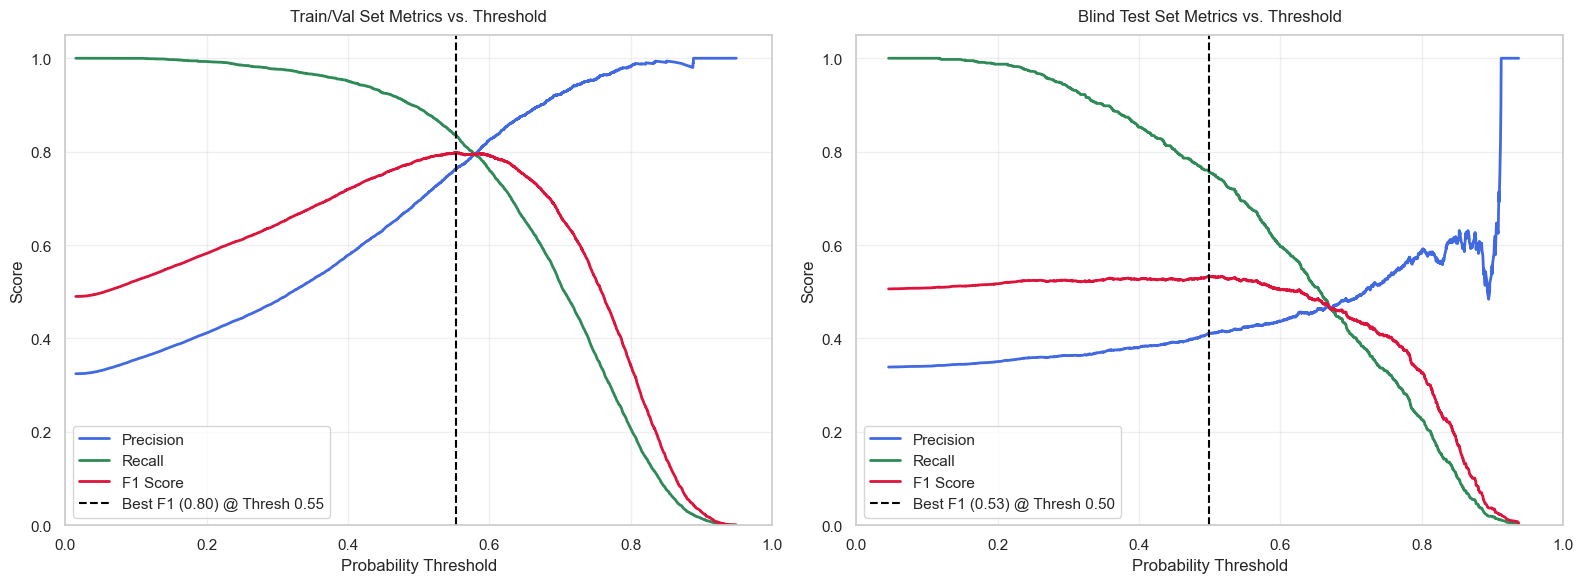

Optimal Probability Threshold (from Test Set): 0.4986

Classification Report on BLIND TEST SET at Optimal Threshold:
              precision    recall  f1-score   support

    Safe (0)       0.78      0.44      0.57      1533
   Risky (1)       0.41      0.76      0.53       785

    accuracy                           0.55      2318
   macro avg       0.60      0.60      0.55      2318
weighted avg       0.66      0.55      0.56      2318



In [16]:
# %%
# =========================================================
# 7. RISK CLASSIFIER THRESHOLD TUNING & PLOTS
# =========================================================
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, classification_report
import numpy as np

print("\n--- RISK CLASSIFIER EVALUATION (VALIDATION VS TEST) ---")

# Get probabilities for both sets
# Note: X_train_val here represents the data the model was just trained on in Step 6
val_risk_proba = pipe_risk.predict_proba(X_train_val)[:, 1]
test_risk_proba = pipe_risk.predict_proba(X_test)[:, 1]

def plot_metrics_vs_threshold(y_true, y_proba, ax, title):
    """Helper function to plot Precision, Recall, and F1 against thresholds."""
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)
    
    # Compute F1 scores for each threshold (ignoring the last precision/recall value which has no corresponding threshold)
    f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
    
    # Find optimal threshold based on Max F1
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    max_f1 = f1_scores[optimal_idx]
    
    # Plotting lines
    ax.plot(thresholds, precisions[:-1], label='Precision', color='royalblue', linewidth=2)
    ax.plot(thresholds, recalls[:-1], label='Recall', color='seagreen', linewidth=2)
    ax.plot(thresholds, f1_scores, label='F1 Score', color='crimson', linewidth=2)
    
    # Highlight optimal threshold
    ax.axvline(optimal_threshold, color='black', linestyle='--', 
               label=f'Best F1 ({max_f1:.2f}) @ Thresh {optimal_threshold:.2f}')
    
    # Formatting
    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel("Probability Threshold")
    ax.set_ylabel("Score")
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(loc='lower left')
    ax.grid(True, alpha=0.3)
    
    return optimal_threshold

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Train+Val (In-Sample)
val_optimal_thresh = plot_metrics_vs_threshold(
    y_train_val_risk, val_risk_proba, axes[0], "Train/Val Set Metrics vs. Threshold"
)

# Plot 2: Test (Out-of-Sample)
test_optimal_thresh = plot_metrics_vs_threshold(
    y_test_risk, test_risk_proba, axes[1], "Blind Test Set Metrics vs. Threshold"
)

plt.tight_layout()
save_and_upload_plot(fig, "RISK_CLASSIFIER_EVALUATION_VALIDATION_VS_TEST")
plt.show()

# Final classification report uses the optimal threshold found on the Test set
# (Or you could logically choose to use val_optimal_thresh if you want to strictly use in-sample tuning)
print(f"Optimal Probability Threshold (from Test Set): {test_optimal_thresh:.4f}")

final_risk_preds = (test_risk_proba >= test_optimal_thresh).astype(int)
print("\nClassification Report on BLIND TEST SET at Optimal Threshold:")
print(classification_report(y_test_risk, final_risk_preds, target_names=["Safe (0)", "Risky (1)"]))

In [17]:
# =========================================================
# 7.5 LOG METRICS TO BIGQUERY
# =========================================================
from datetime import datetime

print("\nLogging evaluation metrics to BigQuery...")

metrics_records = []
run_date = datetime.now().date()

# 1. Extract Regression Metrics
targets = [
    ('MAX_UPSIDE', val_summary['upside'], test_summary['upside']),
    ('MAX_DRAWDOWN', val_summary['drawdown'], test_summary['drawdown']),
    ('AVG_PRICE', val_summary['avg_price'], test_summary['avg_price'])
]

for target_name, val_dict, test_dict in targets:
    for metric_name in ['mae', 'rmse', 'mse', 'mape', 'wape', 'r2']:
        metrics_records.append({
            'training_date': run_date,
            'target_variable': target_name,
            'metric_name': metric_name.upper(),
            'validation_score': val_dict[metric_name],
            'test_score': test_dict[metric_name]
        })

# 2. Extract Classification Metrics
metrics_records.append({
    'training_date': run_date,
    'target_variable': 'RISK_MODEL',
    'metric_name': 'PR-AUC',
    'validation_score': val_summary['risk_auc'],
    'test_score': test_summary['risk_auc']
})

metrics_records.append({
    'training_date': run_date,
    'target_variable': 'RISK_MODEL',
    'metric_name': 'OPTIMAL_THRESHOLD',
    'validation_score': val_optimal_thresh, # From the plotting block
    'test_score': test_optimal_thresh
})

# 3. Upload to BigQuery
df_metrics_log = pd.DataFrame(metrics_records)
METRICS_TABLE = f"{GCP_PROJECT_ID}.predictions.model_metrics_log"

job_config = bigquery.LoadJobConfig(
    write_disposition="WRITE_APPEND",
    schema_update_options=[bigquery.SchemaUpdateOption.ALLOW_FIELD_ADDITION]
)

try:
    job = bq_client.load_table_from_dataframe(df_metrics_log, METRICS_TABLE, job_config=job_config)
    job.result()
    print(f"✅ Successfully logged {job.output_rows} metric rows to {METRICS_TABLE}.")
except Exception as e:
    print(f"❌ Failed to log metrics: {e}")


Logging evaluation metrics to BigQuery...
✅ Successfully logged 20 metric rows to adk-mini-project.predictions.model_metrics_log.



--- EVALUATING CLASSIFIER AT MULTIPLE THRESHOLDS ---
📈 Uploaded plot to gs://adk-mini-project-ml-artifacts/runs/2026-06-08/plots/confusion_matrix_aggressive_0_45.png


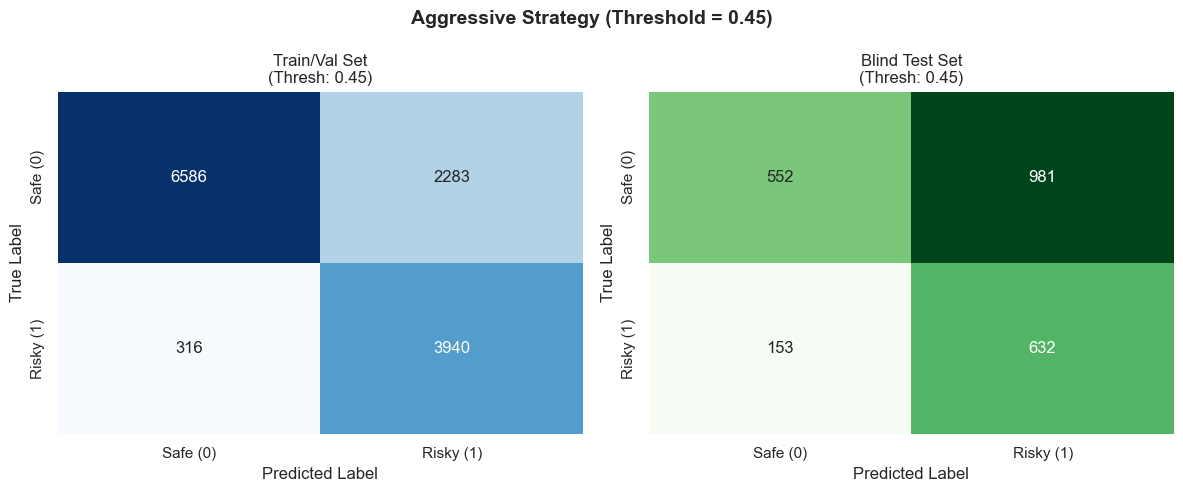

[Aggressive Test] Recall: 80.51% | Precision: 39.18%
📈 Uploaded plot to gs://adk-mini-project-ml-artifacts/runs/2026-06-08/plots/confusion_matrix_balanced_0_5.png


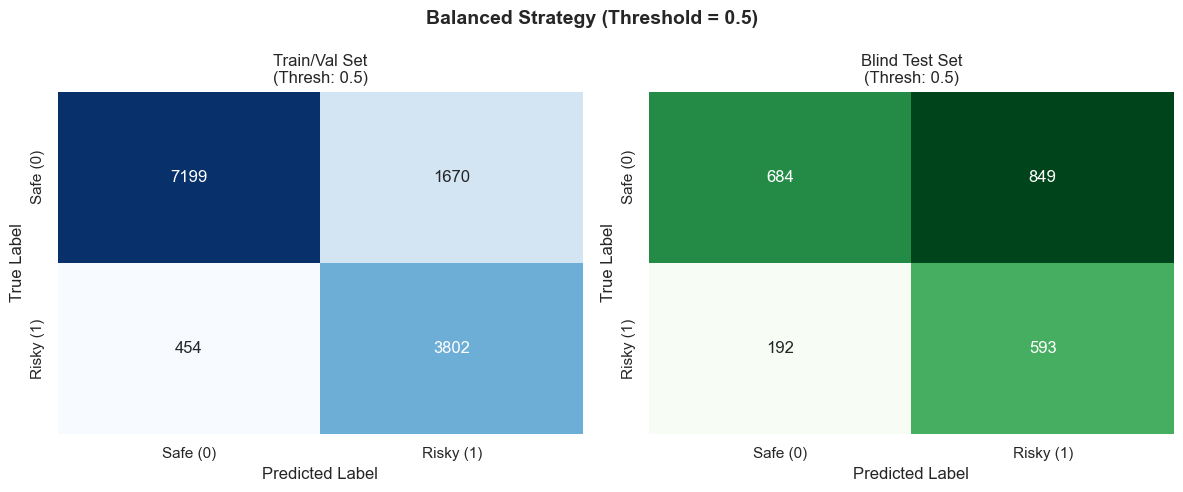

[Balanced Test] Recall: 75.54% | Precision: 41.12%
📈 Uploaded plot to gs://adk-mini-project-ml-artifacts/runs/2026-06-08/plots/confusion_matrix_lenient_0_55.png


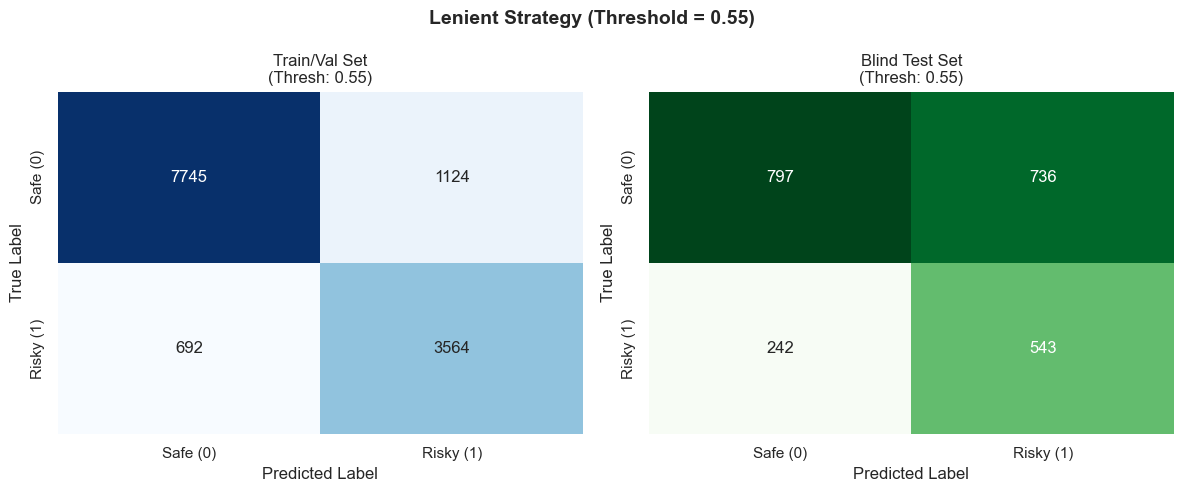

[Lenient Test] Recall: 69.17% | Precision: 42.46%


In [18]:
# %%
# =========================================================
# 8. CONFUSION MATRICES ACROSS DIFFERENT THRESHOLDS
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("\n--- EVALUATING CLASSIFIER AT MULTIPLE THRESHOLDS ---")

# Define the threshold strategies
threshold_strategies = {
    "Aggressive": 0.45,
    "Balanced": 0.50,
    "Lenient": 0.55
}

# Iterate through each strategy and plot side-by-side confusion matrices
for strategy_name, thresh in threshold_strategies.items():
    # 1. Apply the threshold to get binary predictions
    val_preds = (val_risk_proba >= thresh).astype(int)
    test_preds = (test_risk_proba >= thresh).astype(int)
    
    # 2. Compute confusion matrices
    cm_val = confusion_matrix(y_train_val_risk, val_preds)
    cm_test = confusion_matrix(y_test_risk, test_preds)
    
    # 3. Setup the figure
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f"{strategy_name} Strategy (Threshold = {thresh})", fontsize=14, fontweight='bold')
    
    # 4. Plot Train/Val Confusion Matrix (Left)
    sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
                xticklabels=["Safe (0)", "Risky (1)"], 
                yticklabels=["Safe (0)", "Risky (1)"])
    axes[0].set_title(f"Train/Val Set\n(Thresh: {thresh})")
    axes[0].set_xlabel("Predicted Label")
    axes[0].set_ylabel("True Label")
    
    # 5. Plot Blind Test Confusion Matrix (Right)
    # Using a different color map (Greens) to distinguish the test set visually
    sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
                xticklabels=["Safe (0)", "Risky (1)"], 
                yticklabels=["Safe (0)", "Risky (1)"])
    axes[1].set_title(f"Blind Test Set\n(Thresh: {thresh})")
    axes[1].set_xlabel("Predicted Label")
    axes[1].set_ylabel("True Label")
    
    clean_filename = f"confusion_matrix_{strategy_name.lower()}_{str(thresh).replace('.', '_')}"
    

    plt.tight_layout()
    save_and_upload_plot(fig, clean_filename)
    plt.show()

    # Optional: Print a quick summary of the tradeoff for the test set
    tn, fp, fn, tp = cm_test.ravel()
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    print(f"[{strategy_name} Test] Recall: {recall:.2%} | Precision: {precision:.2%}")

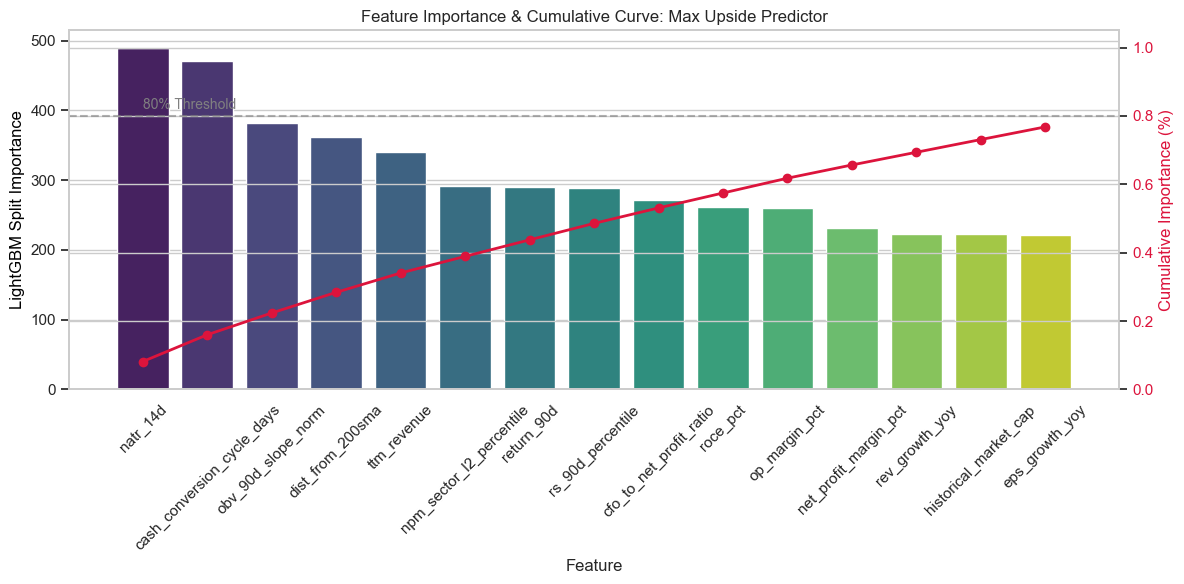

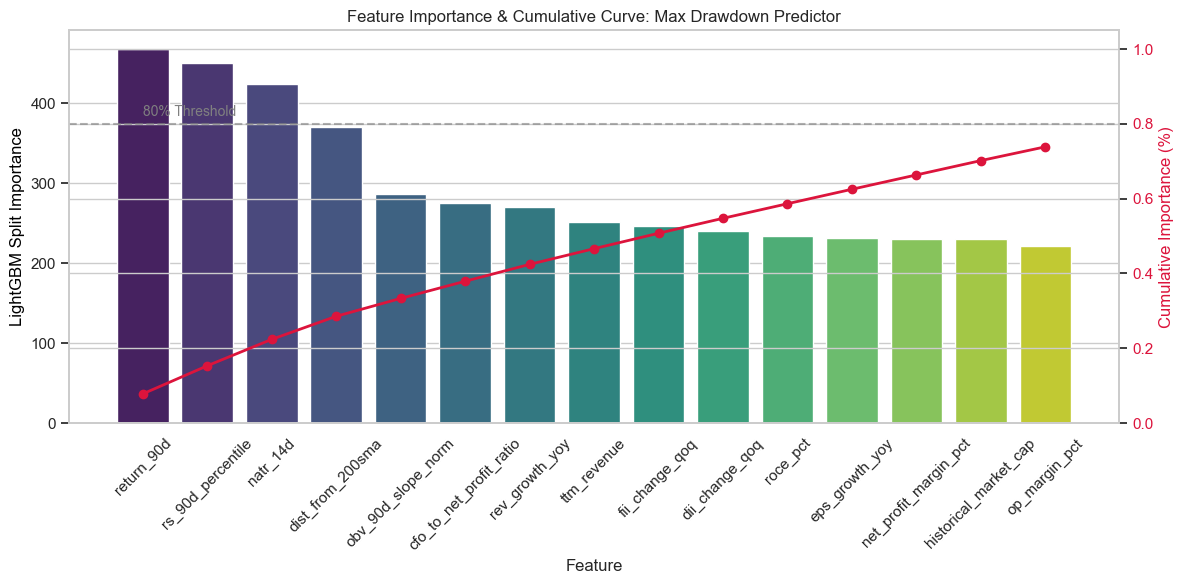

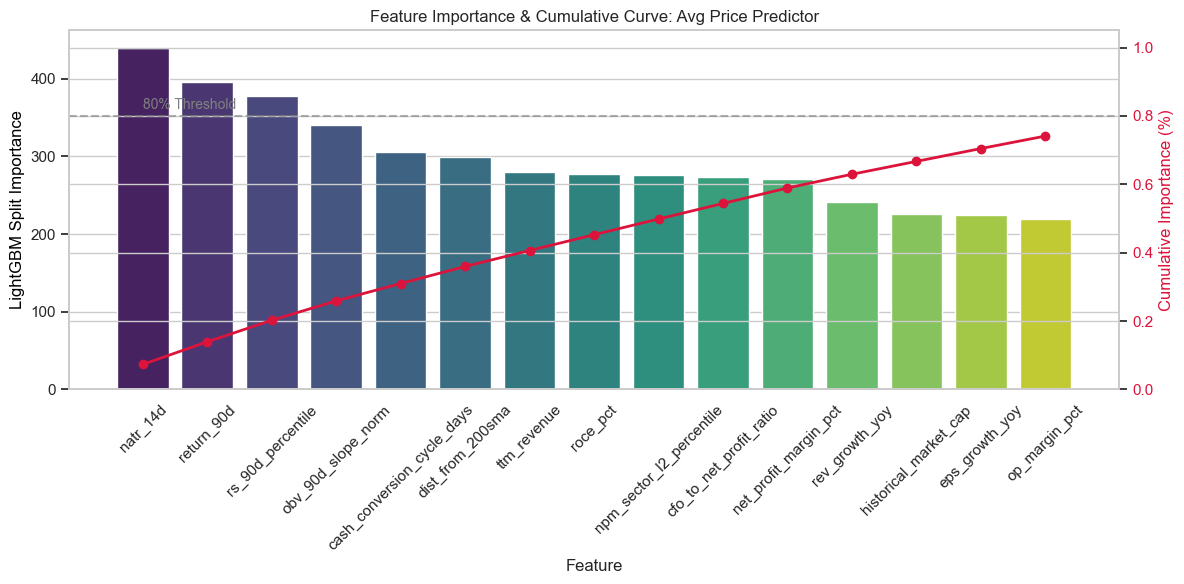

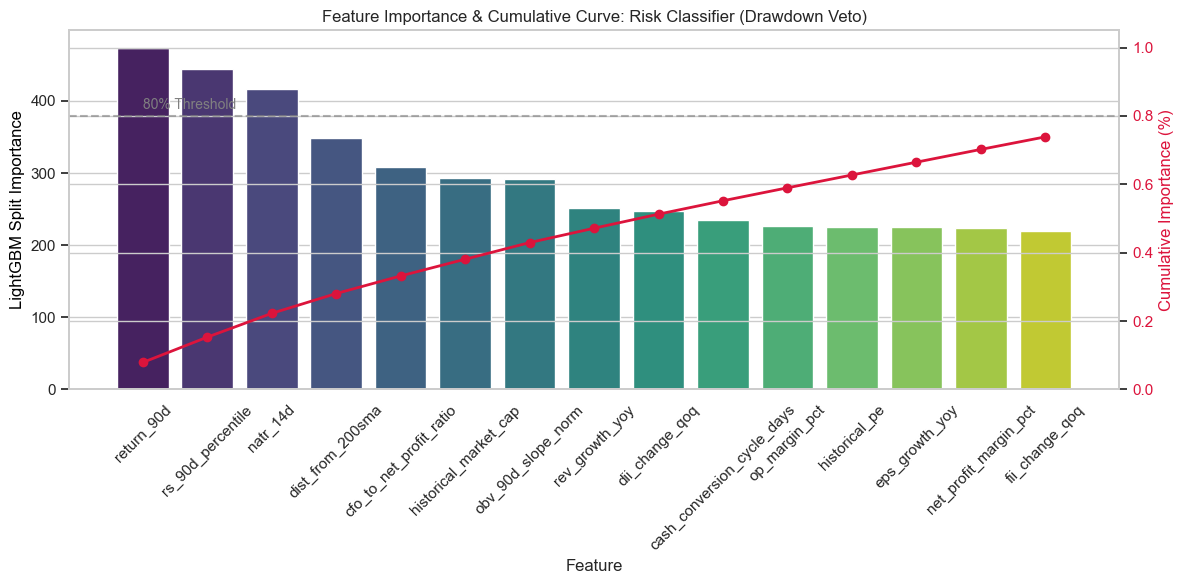

In [19]:
# %%
# =========================================================
# 8. FEATURE IMPORTANCE & CUMULATIVE CURVES
# =========================================================
def plot_feature_importance_with_curve(pipeline, title, top_n=15):
    # Extract the LightGBM model from the pipeline
    model = pipeline.named_steps['model']
    importances = model.feature_importances_
    
    # Create DataFrame and sort
    feat_imp = pd.DataFrame({'Feature': features, 'Importance': importances})
    feat_imp = feat_imp.sort_values(by='Importance', ascending=False).reset_index(drop=True)
    
    # Calculate Cumulative Importance (The Curve)
    feat_imp['Cumulative_Importance'] = feat_imp['Importance'].cumsum() / feat_imp['Importance'].sum()
    
    # Slice the top N features for visualization
    plot_data = feat_imp.head(top_n)
    
    fig, ax1 = plt.subplots(figsize=(12, 6))
    
    # Plot 1: Bar Chart of Individual Importances
    sns.barplot(x='Feature', y='Importance', data=plot_data, palette='viridis', ax=ax1)
    ax1.set_ylabel('LightGBM Split Importance', color='black')
    ax1.tick_params(axis='x', rotation=45)
    
    # Plot 2: Cumulative Importance Line Curve on Secondary Axis
    ax2 = ax1.twinx()
    ax2.plot(plot_data.index, plot_data['Cumulative_Importance'], color='crimson', marker='o', linewidth=2, label='Cumulative Curve')
    ax2.set_ylabel('Cumulative Importance (%)', color='crimson')
    ax2.tick_params(axis='y', labelcolor='crimson')
    ax2.set_ylim(0, 1.05)
    
    # Add gridline for the 80% importance threshold
    ax2.axhline(0.80, color='gray', linestyle='--', alpha=0.6)
    ax2.text(0, 0.82, "80% Threshold", color='gray', fontsize=10)
    
    plt.title(f"Feature Importance & Cumulative Curve: {title}")
    plt.tight_layout()
    plt.show()

# Generate curves for all three Regression Models
plot_feature_importance_with_curve(pipe_upside, "Max Upside Predictor")
plot_feature_importance_with_curve(pipe_drawdown, "Max Drawdown Predictor")
plot_feature_importance_with_curve(pipe_avg, "Avg Price Predictor")

# Generate curve for the Risk Classifier
plot_feature_importance_with_curve(pipe_risk, "Risk Classifier (Drawdown Veto)")

Calculating Permutation Importance for Max Upside Predictor (This may take a minute...)


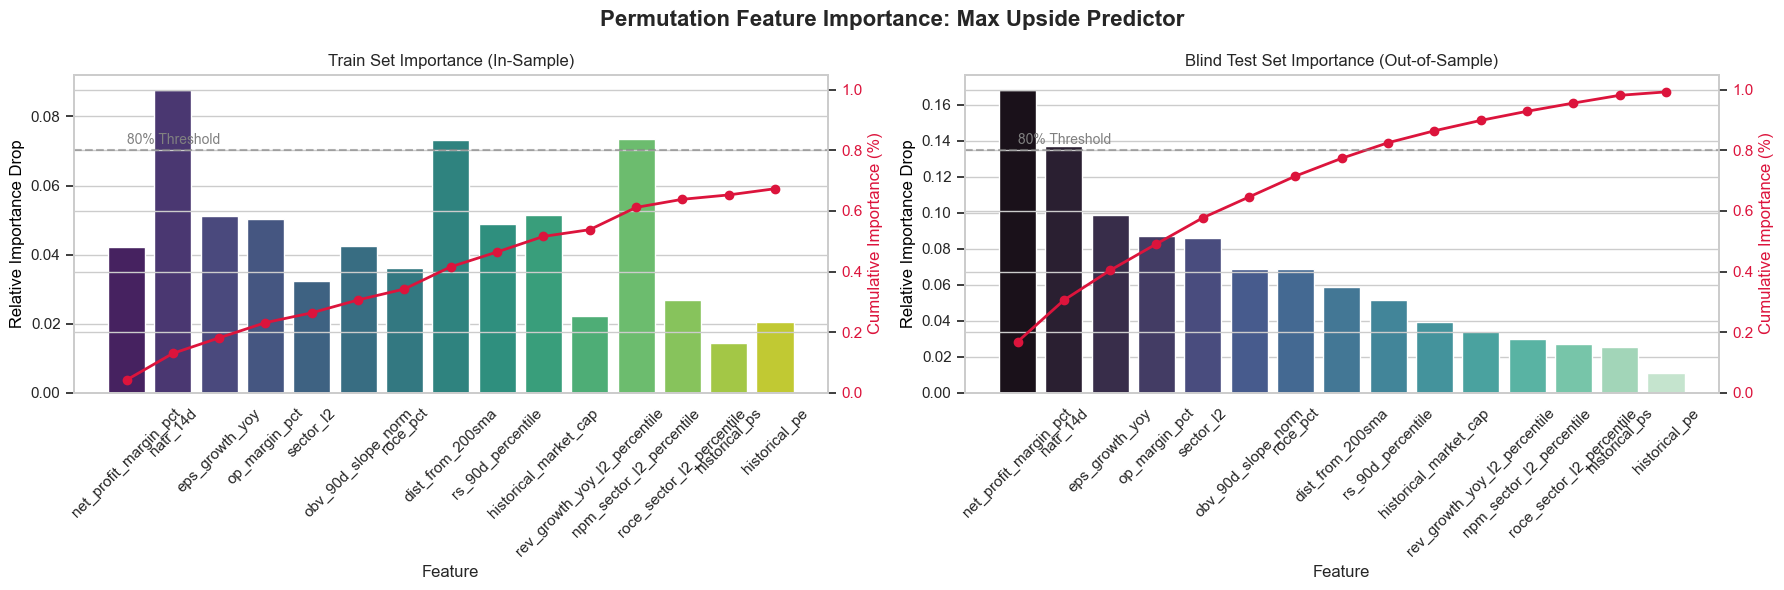

Calculating Permutation Importance for Max Drawdown Predictor (This may take a minute...)


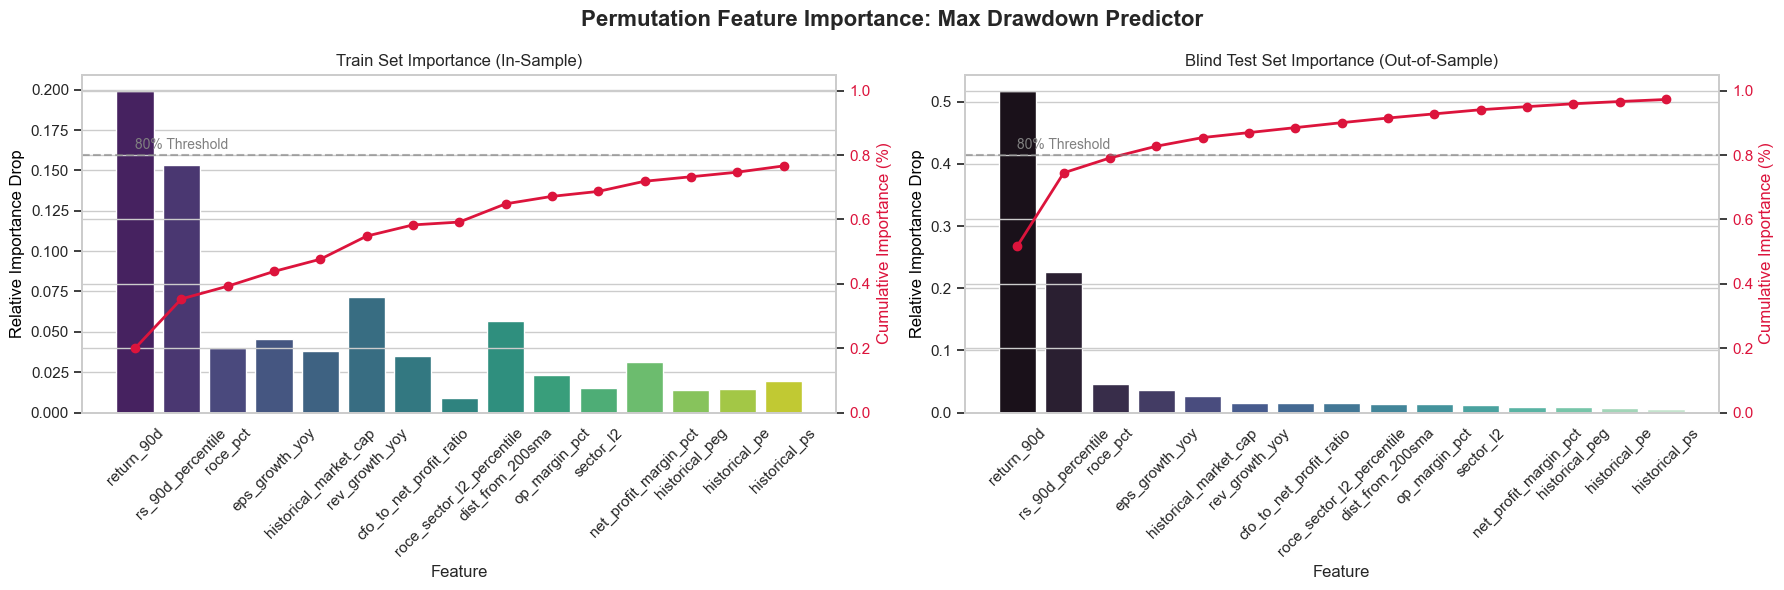

Calculating Permutation Importance for Avg Price Predictor (This may take a minute...)


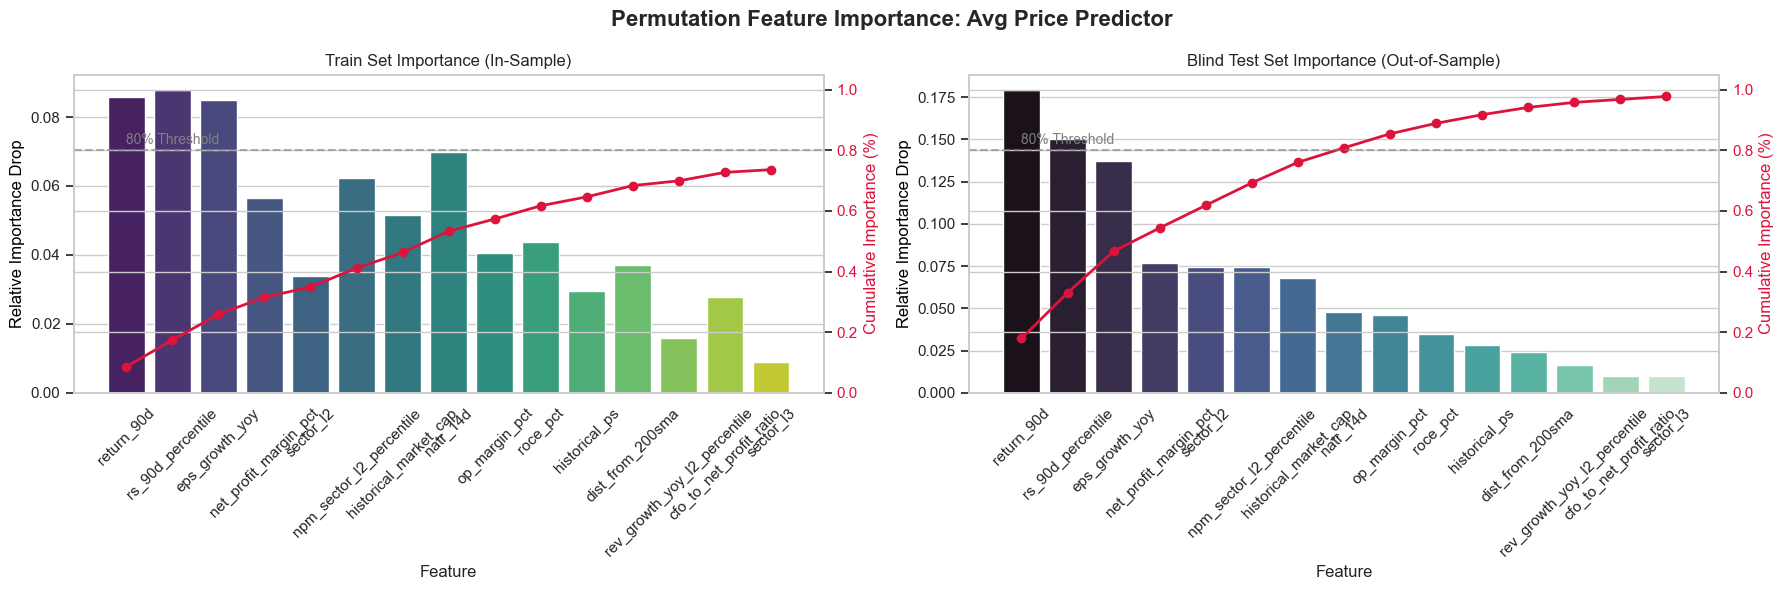

Calculating Permutation Importance for Risk Classifier (Drawdown Veto) (This may take a minute...)


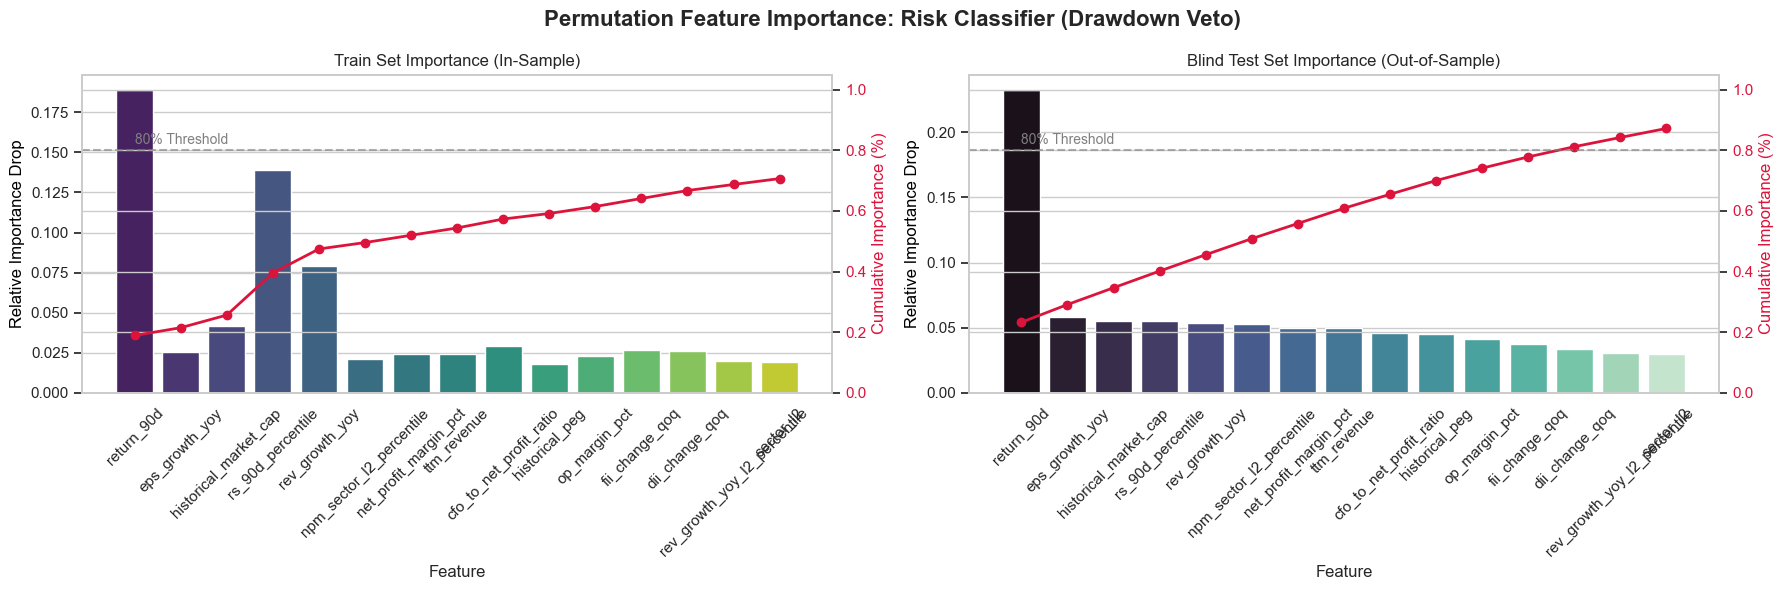

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# =========================================================
# 8. TRAIN VS TEST FEATURE IMPORTANCE (PERMUTATION)
# =========================================================

def plot_train_test_importance(pipeline, X_train, y_train, X_test, y_test, title, top_n=15):
    """
    Calculates and plots Permutation Importance for both Train and Test sets.
    """
    print(f"Calculating Permutation Importance for {title} (This may take a minute...)")
    
    # Calculate Permutation Importance for Train
    train_result = permutation_importance(
        pipeline, X_train, y_train, n_repeats=5, random_state=42, n_jobs=-1
    )
    # Calculate Permutation Importance for Test
    test_result = permutation_importance(
        pipeline, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1
    )
    
    # Create DataFrames
    features = X_train.columns
    
    df_train = pd.DataFrame({'Feature': features, 'Importance': train_result.importances_mean})
    df_test = pd.DataFrame({'Feature': features, 'Importance': test_result.importances_mean})
    
    # Filter out negative importances (features that randomly improved performance when shuffled)
    df_train['Importance'] = df_train['Importance'].clip(lower=0)
    df_test['Importance'] = df_test['Importance'].clip(lower=0)
    
    # Normalize so importances sum to 1 (for the cumulative curve)
    df_train['Normalized_Importance'] = df_train['Importance'] / df_train['Importance'].sum()
    df_test['Normalized_Importance'] = df_test['Importance'] / df_test['Importance'].sum()
    
    # Sort both datasets based on the TEST set's importance (to see what actually works out-of-sample)
    top_features = df_test.sort_values(by='Normalized_Importance', ascending=False).head(top_n)['Feature']
    
    plot_train = df_train[df_train['Feature'].isin(top_features)].set_index('Feature').reindex(top_features).reset_index()
    plot_test = df_test[df_test['Feature'].isin(top_features)].set_index('Feature').reindex(top_features).reset_index()
    
    # Calculate Cumulative Importance
    plot_train['Cumulative'] = plot_train['Normalized_Importance'].cumsum()
    plot_test['Cumulative'] = plot_test['Normalized_Importance'].cumsum()

    # --- PLOTTING ---
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    fig.suptitle(f"Permutation Feature Importance: {title}", fontsize=16, fontweight='bold')

    def draw_subplot(ax, data, title_str, color_palette):
        # Bar Chart
        sns.barplot(x='Feature', y='Normalized_Importance', data=data, palette=color_palette, ax=ax)
        ax.set_ylabel('Relative Importance Drop', color='black')
        ax.tick_params(axis='x', rotation=45)
        ax.set_title(title_str)
        
        # Cumulative Curve
        ax2 = ax.twinx()
        ax2.plot(data.index, data['Cumulative'], color='crimson', marker='o', linewidth=2)
        ax2.set_ylabel('Cumulative Importance (%)', color='crimson')
        ax2.tick_params(axis='y', labelcolor='crimson')
        ax2.set_ylim(0, 1.05)
        
        # 80% Threshold Line
        ax2.axhline(0.80, color='gray', linestyle='--', alpha=0.6)
        ax2.text(0, 0.82, "80% Threshold", color='gray', fontsize=10)

    # Plot Train (Left)
    draw_subplot(axes[0], plot_train, "Train Set Importance (In-Sample)", "viridis")
    
    # Plot Test (Right)
    draw_subplot(axes[1], plot_test, "Blind Test Set Importance (Out-of-Sample)", "mako")

    plt.tight_layout()
    plt.show()

# --- RUNNING THE PLOTS ---
# Make sure to pass your raw datasets (X_train_val, y_train_val, X_test, y_test) 
# into the function alongside the trained pipeline.

plot_train_test_importance(
    pipe_upside, X_train_val, y_train_val_up, X_test, y_test_up, "Max Upside Predictor"
)

plot_train_test_importance(
    pipe_drawdown, X_train_val, y_train_val_down, X_test, y_test_down, "Max Drawdown Predictor"
)

plot_train_test_importance(
    pipe_avg, X_train_val, y_train_val_avg, X_test, y_test_avg, "Avg Price Predictor"
)

plot_train_test_importance(
    pipe_risk, X_train_val, y_train_val_risk, X_test, y_test_risk, "Risk Classifier (Drawdown Veto)"
)

Calculating SHAP Values for Max Upside Predictor...


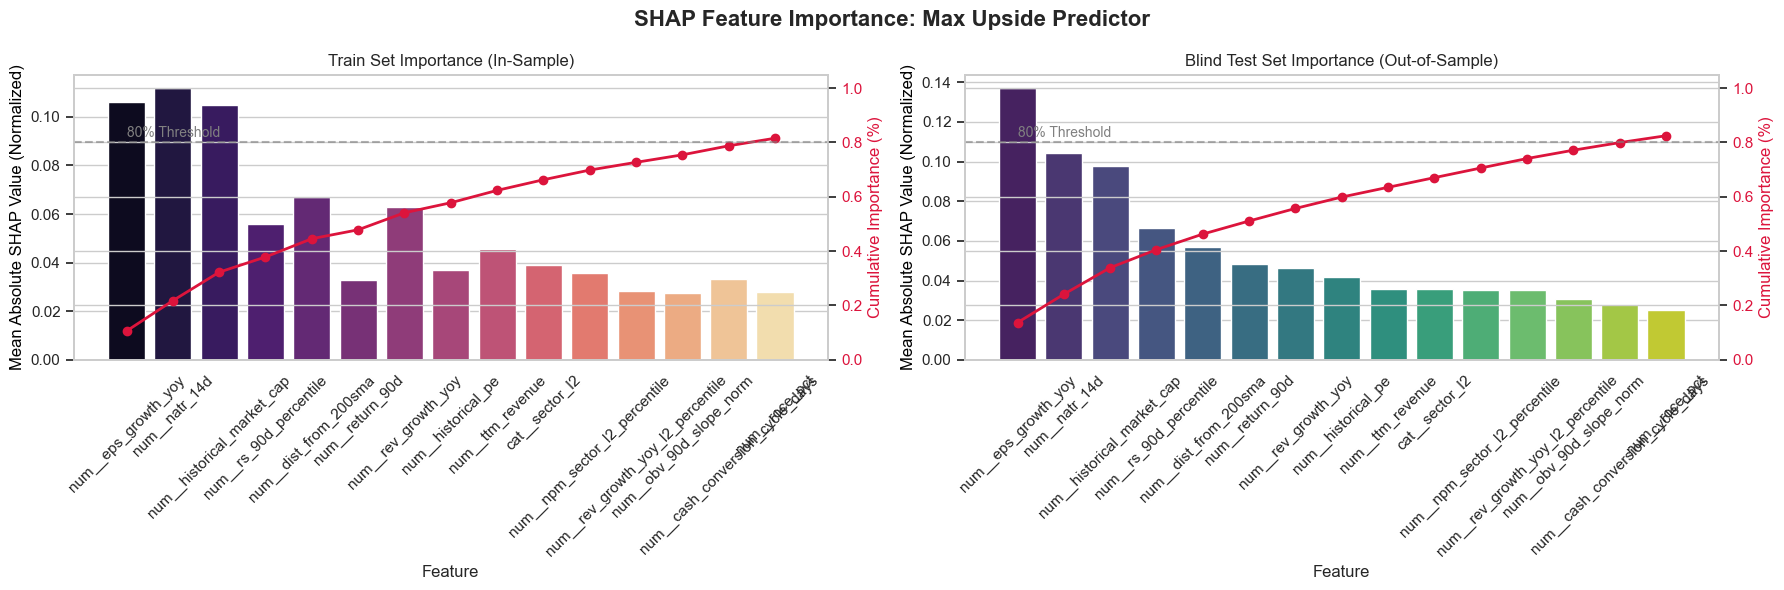

Calculating SHAP Values for Max Drawdown Predictor...


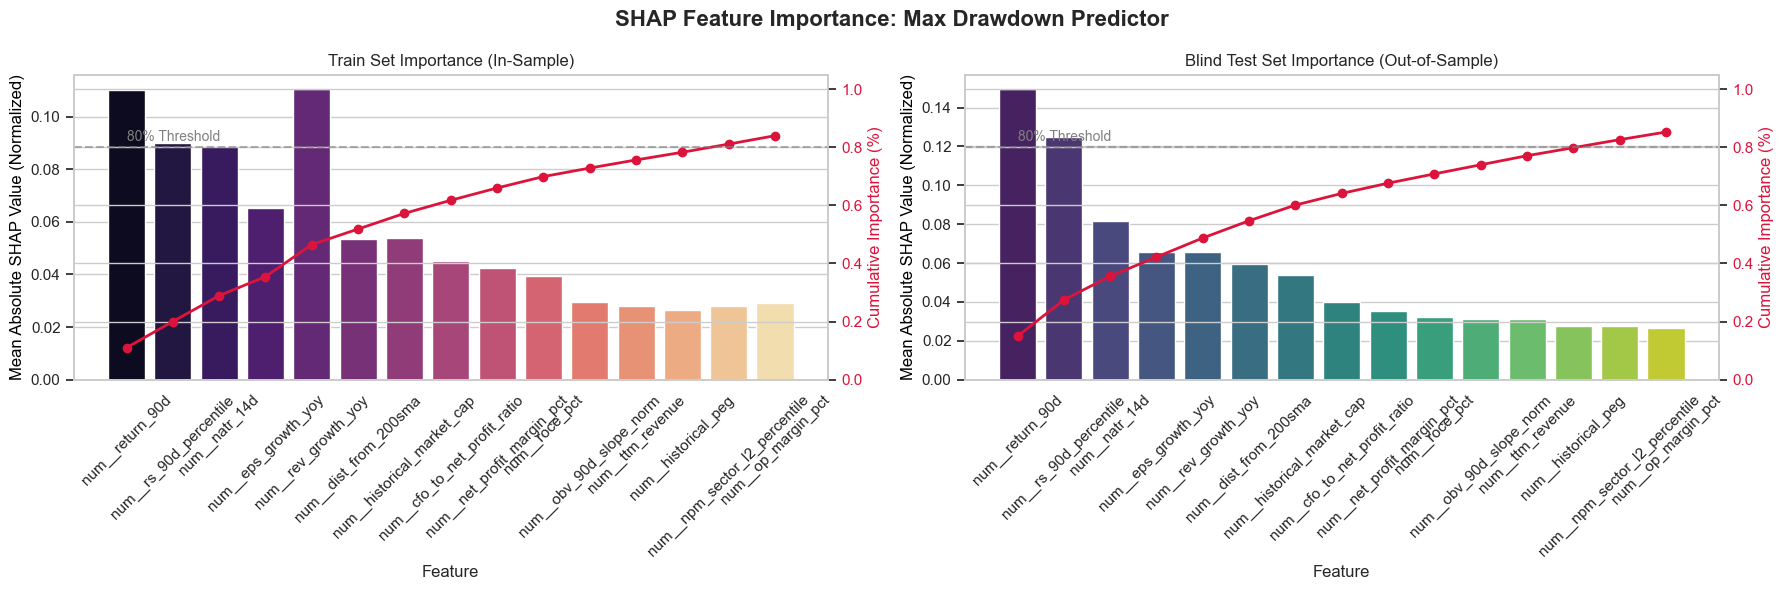

Calculating SHAP Values for Avg Price Predictor...


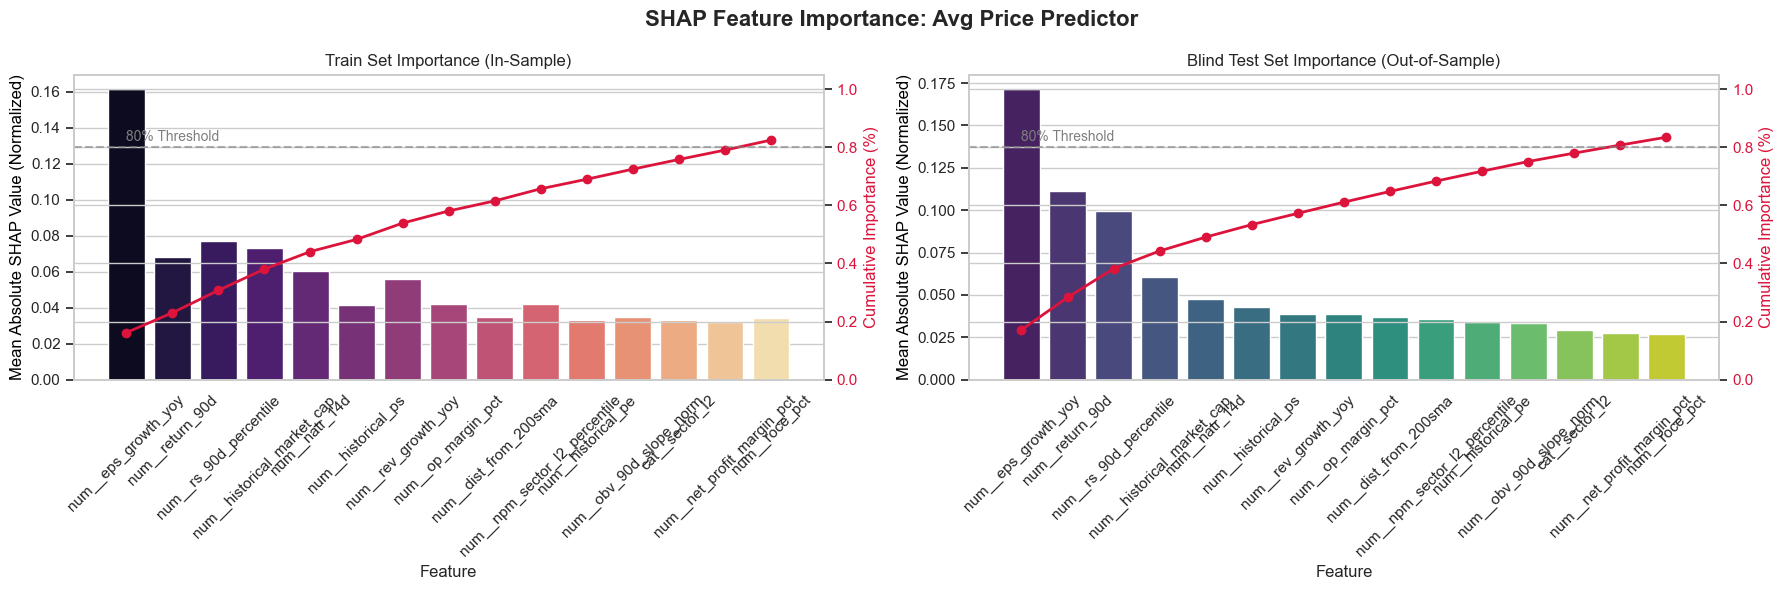

Calculating SHAP Values for Risk Classifier (Drawdown Veto)...


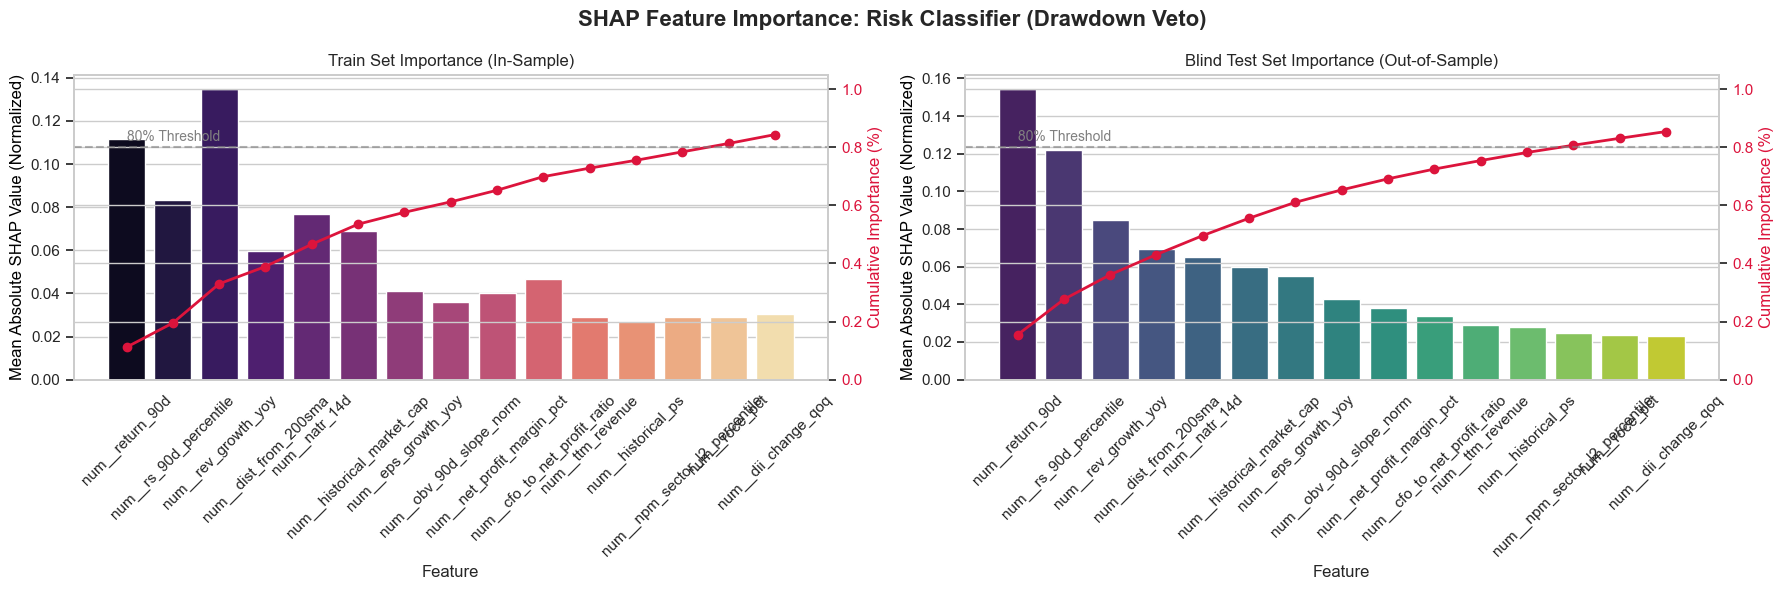

In [21]:
# %%
# =========================================================
# 8. TRAIN VS TEST FEATURE IMPORTANCE (SHAP VALUES)
# =========================================================
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_train_test_shap_importance(pipeline, X_train, X_test, title, top_n=15):
    """
    Calculates and plots SHAP Importance for both Train and Test sets.
    """
    print(f"Calculating SHAP Values for {title}...")
    
    # 1. Extract the preprocessor and the model from the pipeline
    # We assume the last step is the model, and everything before is preprocessing
    preprocessor = pipeline[:-1]
    model = pipeline.named_steps['model']
    
    # 2. Transform the data through the preprocessing steps
    # If the pipeline has no preprocessing, this just returns the raw data
    if len(preprocessor) > 0:
        X_train_tf = preprocessor.transform(X_train)
        X_test_tf = preprocessor.transform(X_test)
        
        # Try to get feature names after transformation (e.g., if OneHotEncoder was used)
        try:
            feature_names = preprocessor.get_feature_names_out()
        except AttributeError:
            feature_names = X_train.columns
    else:
        X_train_tf = X_train
        X_test_tf = X_test
        feature_names = X_train.columns

    # 3. Initialize SHAP TreeExplainer
    explainer = shap.TreeExplainer(model)
    
    # 4. Calculate SHAP values
    shap_values_train = explainer.shap_values(X_train_tf)
    shap_values_test = explainer.shap_values(X_test_tf)
    
    # Handle LightGBM Binary Classification output (returns a list of arrays for [Negative, Positive] classes)
    if isinstance(shap_values_train, list):
        shap_values_train = shap_values_train[1]  # Get SHAP values for the positive class (Risky)
        shap_values_test = shap_values_test[1]

    # 5. Calculate global feature importance (Mean Absolute SHAP Value)
    imp_train = np.abs(shap_values_train).mean(axis=0)
    imp_test = np.abs(shap_values_test).mean(axis=0)
    
    df_train = pd.DataFrame({'Feature': feature_names, 'Importance': imp_train})
    df_test = pd.DataFrame({'Feature': feature_names, 'Importance': imp_test})
    
    # 6. Normalize so importances sum to 100% (for the cumulative curve)
    df_train['Normalized_Importance'] = df_train['Importance'] / df_train['Importance'].sum()
    df_test['Normalized_Importance'] = df_test['Importance'] / df_test['Importance'].sum()
    
    # 7. Sort both datasets based on the TEST set's importance
    top_features = df_test.sort_values(by='Normalized_Importance', ascending=False).head(top_n)['Feature']
    
    plot_train = df_train[df_train['Feature'].isin(top_features)].set_index('Feature').reindex(top_features).reset_index()
    plot_test = df_test[df_test['Feature'].isin(top_features)].set_index('Feature').reindex(top_features).reset_index()
    
    # Calculate Cumulative Importance
    plot_train['Cumulative'] = plot_train['Normalized_Importance'].cumsum()
    plot_test['Cumulative'] = plot_test['Normalized_Importance'].cumsum()

    # --- PLOTTING ---
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    fig.suptitle(f"SHAP Feature Importance: {title}", fontsize=16, fontweight='bold')

    def draw_subplot(ax, data, title_str, color_palette):
        # Bar Chart
        sns.barplot(x='Feature', y='Normalized_Importance', data=data, palette=color_palette, ax=ax)
        ax.set_ylabel('Mean Absolute SHAP Value (Normalized)', color='black')
        ax.tick_params(axis='x', rotation=45)
        ax.set_title(title_str)
        
        # Cumulative Curve
        ax2 = ax.twinx()
        ax2.plot(data.index, data['Cumulative'], color='crimson', marker='o', linewidth=2)
        ax2.set_ylabel('Cumulative Importance (%)', color='crimson')
        ax2.tick_params(axis='y', labelcolor='crimson')
        ax2.set_ylim(0, 1.05)
        
        # 80% Threshold Line
        ax2.axhline(0.80, color='gray', linestyle='--', alpha=0.6)
        ax2.text(0, 0.82, "80% Threshold", color='gray', fontsize=10)

    # Plot Train (Left)
    draw_subplot(axes[0], plot_train, "Train Set Importance (In-Sample)", "magma")
    
    # Plot Test (Right)
    draw_subplot(axes[1], plot_test, "Blind Test Set Importance (Out-of-Sample)", "viridis")

    plt.tight_layout()
    plt.show()

# --- RUNNING THE PLOTS ---
# Notice we don't need to pass the target variables (y_train/y_test) because SHAP 
# explains the model's *predictions* based purely on the X features.

plot_train_test_shap_importance(pipe_upside, X_train_val, X_test, "Max Upside Predictor")
plot_train_test_shap_importance(pipe_drawdown, X_train_val, X_test, "Max Drawdown Predictor")
plot_train_test_shap_importance(pipe_avg, X_train_val, X_test, "Avg Price Predictor")
plot_train_test_shap_importance(pipe_risk, X_train_val, X_test, "Risk Classifier (Drawdown Veto)")